# 01 · The forger and the detective: your first GAN

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/gan_Mnist/blob/main/notebooks/01_intuition_and_a_minimal_gan.ipynb)

**After this notebook you will be able to** explain how a GAN learns without ever being told what a good picture looks like,
train a tiny GAN on numbers and a small one on handwritten digits, and read what the first pictures tell you.

*Time: about 40 minutes (the training cells take roughly six minutes on a laptop CPU in total). No GPU needed.
Prior knowledge: basic Python and NumPy; the idea of a neural network helps but is not required.*

## 1 · The big question

A classifier gets a picture and says "this is a 7". Easy to grade: the right answer is known.
Now the opposite task: **invent a new picture of a handwritten digit** that nobody drew, but that looks as if a person did.
There is no "right answer" to compare with, because there are infinitely many good digits. How can a network learn to do that?

Ian Goodfellow and colleagues (2014) had an elegant idea: *do not grade the pictures yourself, let a second network grade them,
and make the two compete.*

## 2 · Intuition first: a forger and a detective

Picture an art forger and a detective.

- The **forger** (the *generator*) paints fake banknotes. At the start he has never seen a real one: his notes are random scribbles.
- The **detective** (the *discriminator*) gets a pile of notes, some real and some fake, and must say which is which.

At first the detective wins easily and tells the forger *why* (the notes have no pattern, the colours are wrong). The forger uses this
feedback to paint better notes. Then the detective has to look harder, and gets better too. They push each other.
If it goes well, the forger ends up making notes the detective cannot tell apart from real ones.

The forger **never sees a real note**. He only sees how the detective reacted to his fakes. All knowledge about real notes reaches him through the detective.

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/gan_Mnist.git"], check=True)
    os.chdir("gan_Mnist/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import gan as gn
from src.gan import save_figure

gn.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

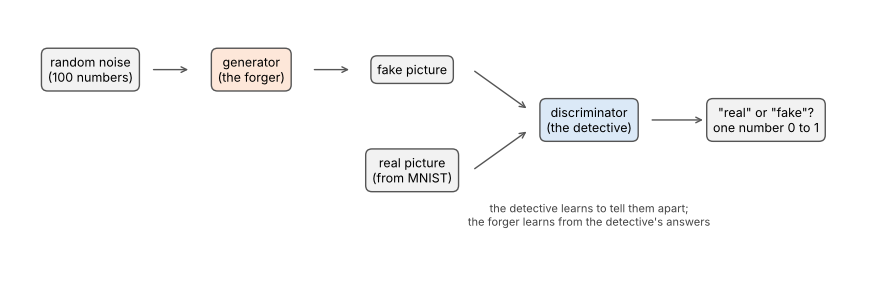

In [2]:
fig = gn.plot_game()
save_figure(fig, "01_the_game.png")
plt.show()

**What to notice.** Random numbers go into the generator; out comes a fake picture. The discriminator receives either a fake or a real picture
and answers with one number between 0 ("fake") and 1 ("real"). Both networks learn from that answer, in opposite directions.

*Figure: the game between the two networks.*

**Math (light).** The competition can be written as one formula that the discriminator $D$ tries to make *large* and the generator $G$ tries to make *small*:

$$\min_G \max_D \; \mathbb{E}_{x}\big[\log D(x)\big] + \mathbb{E}_{z}\big[\log\big(1 - D(G(z))\big)\big]$$

- $x$: a real picture; $D(x)$: the detective's score for it (close to 1 if he is right);
- $z$: random noise; $G(z)$: the fake picture made from it; $D(G(z))$: the score the detective gives to the fake (he wants it close to 0);
- $\mathbb{E}$: "the average over many examples", $\log$: the logarithm, which punishes confident mistakes very hard;
- $\min_G \max_D$: the detective $D$ makes the formula as large as possible, the forger $G$ as small as possible.

In practice (and in the 2022 code of this repository) the forger does not minimise the formula directly. He uses a trick that gives stronger feedback early on:
he is trained as if his fakes *were labelled real*, so that he lowers $-\log D(G(z))$. That is the "please call my fakes real" step you will see in the code.

> **Predict:** if the game ends in a perfect draw, what accuracy will the detective have when he must tell real from fake?

## 3 · A game you can see: numbers instead of pictures

Pictures are hard to look at while the networks are still bad. So first the **same game with single numbers**:
the "real data" are numbers from a bell curve (mean 3, standard deviation 0.6); the forger turns a random number into a new number;
the detective tries to tell real numbers from the forger's. We can *draw* what the forger produces as a histogram.

In [3]:
real_numbers = gn.toy_real_data()
print("real numbers: mean %.2f, standard deviation %.2f" % (real_numbers.mean(), real_numbers.std()))

gn.set_seed()
toy_generator, toy_discriminator = gn.build_toy_generator(), gn.build_toy_discriminator()
noise = np.random.default_rng(1).standard_normal((5000, 1)).astype("float32")

start = time.time()
toy_history, toy_snapshots = gn.train_gan(toy_generator, toy_discriminator, real_numbers, steps=3000, batch_size=128,
                                          snapshot_steps=(0, 100, 300, 1000, 3000), fixed_noise=noise, learning_rate=1e-3)
print(f"trained for 3000 steps in {time.time() - start:.0f} s")
for step_number, numbers in toy_snapshots.items():
    print(f"step {step_number:5d}: generated numbers have mean {numbers.mean():5.2f} and standard deviation {numbers.std():.2f}")

real numbers: mean 3.00, standard deviation 0.60


trained for 3000 steps in 5 s
step     0: generated numbers have mean  0.16 and standard deviation 0.16
step   100: generated numbers have mean  1.03 and standard deviation 0.51
step   300: generated numbers have mean  3.49 and standard deviation 1.11
step  1000: generated numbers have mean  2.92 and standard deviation 0.96
step  3000: generated numbers have mean  3.02 and standard deviation 0.99


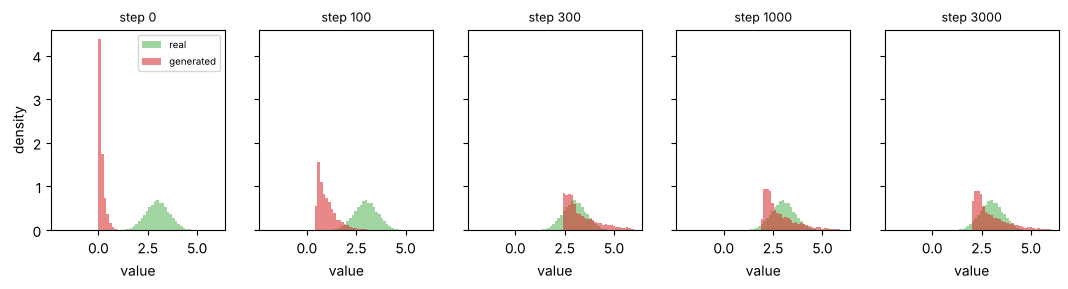

detective, last 200 steps: right on 46% of the real and 54% of the fake numbers
detective's loss, last 200 steps: 0.693   (a coin flip would give ln 2 = 0.693)


In [4]:
fig = gn.plot_toy_progress(real_numbers, toy_snapshots)
save_figure(fig, "01_toy_progress.png")
plt.show()

last = slice(-200, None)
print("detective, last 200 steps: right on %.0f%% of the real and %.0f%% of the fake numbers" %
      (100 * np.mean(toy_history["d_acc_real"][last]), 100 * np.mean(toy_history["d_acc_fake"][last])))
print("detective's loss, last 200 steps: %.3f   (a coin flip would give ln 2 = %.3f)" % (np.mean(toy_history["d_loss"][last]), np.log(2)))

**What to notice** (green = real numbers, red = numbers made by the forger):

- **Step 0:** the forger's numbers sit near 0 with almost no spread (standard deviation 0.16), far from the real ones around 3. The detective wins easily.
- **Steps 100 to 300:** the red histogram moves to the right and overshoots (mean 3.49 at step 300), then settles: mean 2.92 at step 1000 and 3.02 at step 3000, right on the real mean of 3.00.
- **At the end** the detective is right on 46% of the real and 54% of the fake numbers and his loss is 0.693, the value of a coin flip: the game ended in a **draw**, as we predicted.
- **But a draw is not a perfect forger.** The generated numbers still spread wider than the real ones (standard deviation 0.99 versus 0.60) and do not have the bell shape: there is a sharp edge near 2.2 and a long tail to the right. This detective is a very small network and could not see the difference. *A GAN is only as good as its detective.*

*Figure: histograms of the real numbers (green) and the forger's numbers (red) at five moments of training.*

### Check yourself

1. At step 0 the forger produces numbers near 0 and the real numbers are near 3. Why can the detective win easily at that moment?
2. Why does the forger never need a list of real numbers to learn?

<details>
<summary>Answers</summary>


1. The two groups lie far apart, so a simple rule ("anything above 1.5 is real") already separates them.
2. He only needs the detective's answers: the direction in which a fake would have to move to look more real is part of the feedback he receives.

</details>

## 4 · From numbers to digits

Now the real task. The real data are the 60,000 handwritten digits of MNIST (see [`data/README.md`](../data/README.md) for the licence);
the forger turns 100 random numbers into a 28 x 28 picture.

training pictures: (60000, 28, 28, 1)   pixel values from 0.0 to 1.0


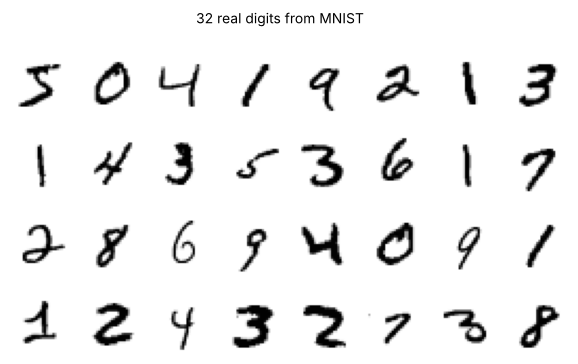

In [5]:
digits = gn.load_mnist()
print("training pictures:", digits.shape, "  pixel values from", digits.min(), "to", digits.max())

fig = gn.plot_grid(digits[:32], 4, 8, title="32 real digits from MNIST")
save_figure(fig, "01_real_digits.png")
plt.show()

**What to notice.** These are the pictures the detective will see as "real". Note the variety: thin and thick strokes, slanted and upright digits, different ways to write a 4 or a 7.
(We never use the labels 0 to 9: the forger is not asked for a *specific* digit, only for a believable one.)

*Figure: 32 real training pictures.*

In [6]:
gn.set_seed()
generator, discriminator = gn.build_generator(width=32), gn.build_discriminator(width=32)
print(f"generator: {generator.count_params():,} numbers to learn      discriminator: {discriminator.count_params():,} numbers to learn")
generator.summary()

generator: 192,769 numbers to learn      discriminator: 11,137 numbers to learn


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 1568)           │       158,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 32)     │        16,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        16,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │         1,569 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 192,769 (753.00 KB)

 Trainable params: 192,769 (753.00 KB)

 Non-trainable params: 0 (0.00 B)

**What to notice.** The generator starts with a layer that turns 100 noise numbers into a small 7 x 7 picture with 32 channels, then
enlarges it twice (7 to 14 to 28 pixels) with *transposed convolutions* (a convolution that makes the picture bigger instead of smaller) and ends with one
channel of pixels between 0 and 1. The discriminator is a small convolutional classifier like the ones in an image-classification tutorial.
These are the shapes of the 2022 version, **made smaller** (32 filters instead of 128) so that training takes a few minutes on a laptop CPU.

Before training, the forger knows nothing. Here is what he paints from 8 different noise vectors:

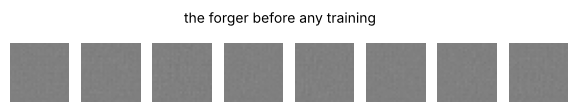

In [7]:
fixed_noise = np.random.default_rng(0).standard_normal((8, gn.NOISE_DIM)).astype("float32")
fig = gn.plot_grid(generator(fixed_noise, training=False).numpy(), 1, 8, title="the forger before any training")
plt.show()

**What to notice.** Grey static: no strokes, no digits, as expected. All eight pictures look alike because the untrained network
maps all noise to nearly the same grey texture.

## 5 · Train the first GAN

In every step the two networks take turns:

1. **Detective's turn:** he gets 64 real and 64 fake pictures and learns to score the real ones near 1 and the fake ones near 0.
2. **Forger's turn:** he makes 64 new fakes and is rewarded when the detective scores them as real (this is the "please call my fakes real" step).

We train for **3,000 steps** (about three passes over the data) with batches of 64 pictures, seed 42. This is a *small* experiment on purpose:
the original code ran 100 epochs (23,400 steps); a CPU cannot do that in a tutorial. We keep the same 8 noise vectors throughout, so we can watch the *same* eight pictures evolve.

In [8]:
start = time.time()
history, snapshots = gn.train_gan(generator, discriminator, digits, steps=3000, batch_size=64,
                                  snapshot_steps=(0, 250, 500, 1000, 2000, 3000), fixed_noise=fixed_noise)
print(f"trained for 3000 steps in {time.time() - start:.0f} s")

trained for 3000 steps in 280 s


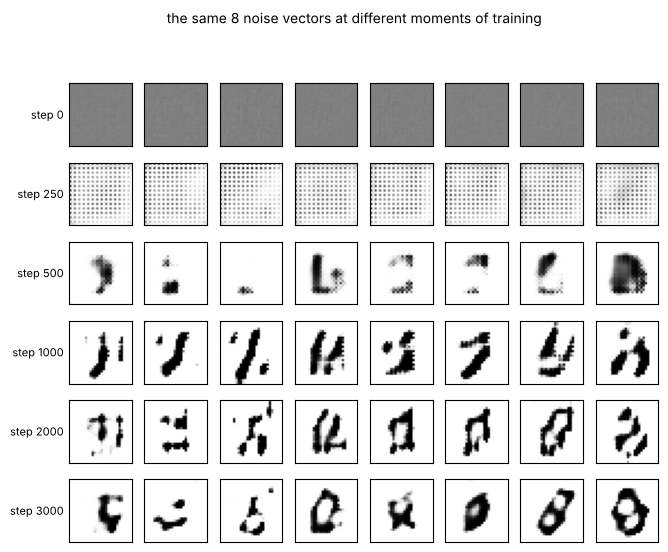

In [9]:
fig = gn.plot_progress(snapshots, columns=8)
fig.suptitle("the same 8 noise vectors at different moments of training", y=1.0, fontsize=10)
save_figure(fig, "01_progress.png")
plt.show()

**What to notice.** Each row shows the *same* eight noise vectors at a different moment:

- **Step 0:** uniform grey, as expected.
- **Step 250:** a faint regular pattern of dots (a "checkerboard", typical of transposed convolutions), but no strokes.
- **Step 500:** the first dark blobs and strokes, in random places.
- **Step 1000:** thick, stroke-like shapes: they look like pieces of handwriting, but no digit is recognisable.
- **Steps 2000 to 3000:** more structure and closed loops (in the last two columns at step 3000 something like a 0 or an 8), but most pictures are still not clean digits.

After about three passes over the data the forger has learned *what kind of thing* a digit picture is (dark strokes on white) but has not yet learned to draw real digits. We claim no more than this; no quality measure was computed.

*Figure: the same eight noise vectors passed through the generator at steps 0, 250, 500, 1000, 2000 and 3000.*

In [10]:
last = slice(-300, None)
print("detective, last 300 steps: right on %.0f%% of the real and %.0f%% of the fake pictures" %
      (100 * np.mean(history["d_acc_real"][last]), 100 * np.mean(history["d_acc_fake"][last])))
print("detective's loss %.3f   forger's loss %.3f" % (np.mean(history["d_loss"][last]), np.mean(history["g_loss"][last])))

detective, last 300 steps: right on 60% of the real and 61% of the fake pictures
detective's loss 0.665   forger's loss 0.747


**What to notice.** At the end the detective is right on about 60% of the real and 61% of the fake pictures (guessing would give 50%): he is only a little better than a coin flip, and his loss (0.665) is close to the coin-flip value 0.693. The forger's loss is 0.747.
This does **not** mean that the forger is perfect: the pictures above are still rough. Remember the toy game, where a draw also hid a wrong spread. The numbers tell us who is winning the game, not how good the pictures are.

### Check yourself

1. The forger's loss goes *up* when the detective gets better. Is a rising generator loss always bad news?
2. Why do we use the same 8 noise vectors at every snapshot?

<details>
<summary>Answers</summary>


1. Not necessarily. In a game the two losses are linked: when the detective improves, the forger's task gets harder, so his loss can rise even though his pictures improve. Loss curves of GANs are hard to read (this is the main topic of notebook 02); always look at the pictures.
2. Then the pictures differ only because the generator changed, not because we drew new noise: it is a fair "before and after".

</details>

## 6 · Common mistakes

- **Expecting a normal loss curve.** In a GAN the loss is the score in a game, not a distance to a goal; a flat curve can mean a draw, a rising one can mean progress.
- **Looking at numbers instead of pictures.** Early on, the samples tell you more than the losses do.
- **Using the labels.** A plain GAN does not know about the digits 0 to 9; asking for a specific digit needs a conditional GAN (not covered here).
- **Forgetting the seed.** GAN training is chaotic: without a fixed seed two runs can look very different.
- **Judging quality by eye only.** What looks "like a digit" depends on who looks; there are numerical measures, but they too have limits (not used in this tutorial).

## 7 · Recap

- A GAN is a game: a generator makes fakes, a discriminator tells real from fake, and each improves by competing with the other.
- The generator never sees real data directly; everything it learns comes from the discriminator's answers.
- With small settings and a few thousand steps a GAN already finds stroke-like shapes, but the digits are still rough, and in the end the pictures, not the loss curves, tell us how far the game has come.

**Next:** notebook 02 follows the training for longer, with samples across epochs, loss curves, and the two classic failures: instability and *mode collapse*.